In [1]:
!pwd

/data/home/mayppcy/patient_case_search/master_thesis/baseline_models/CHESS


In [70]:
import json
from pathlib import Path

def bold(text):
    return f"\033[1m{text}\033[0m"

RED, GREEN, YELLOW, BLUE, RESET = "\033[91m", "\033[92m", "\033[93m","\033[94m","\033[0m"

In [3]:
path = './data/dev/dev.json'
with open(path, "r", encoding="utf-8") as f:
    dev = json.load(f)
print(len(dev))

1534


In [4]:
path = './data/dev/dev_subsample.json'
with open(path, "r", encoding="utf-8") as f:
    dev_subsample = json.load(f)
print(f"len(dev_subsample): {len(dev_subsample)}")

dev_subsample_qid = []
for i in range(len(dev_subsample)):
    dev_subsample_qid.append(dev_subsample[i]['question_id'])
    
path = './results/dev/CHESS_IR_CG_UT/dev_subsample_199/2026-10-22T04:45:47.607234/-statistics.json'
with open(path, "r", encoding="utf-8") as f:
    stat_1 = json.load(f)
print(f"len(stat_1): {len(stat_1)}")

path = './results/dev/CHESS_IR_CG_UT/dev_subsample_199/2026-10-22T04:45:47.607234/-predictions.json'
with open(path, "r", encoding="utf-8") as f:
    pred_1 = json.load(f)
print(f"len(pred_1): {len(pred_1)}")
    
path = './results/dev/CHESS_IR_CG_UT/dev_subsample_300/2026-10-28T05:10:42.285834/-statistics.json'
with open(path, "r", encoding="utf-8") as f:
    stat_2 = json.load(f)
print(f"len(stat_2): {len(stat_2)}")

path = './results/dev/CHESS_IR_CG_UT/dev_subsample_300/2026-10-28T05:10:42.285834/-predictions.json'
with open(path, "r", encoding="utf-8") as f:
    pred_2 = json.load(f)
print(f"len(pred_2): {len(pred_2)}")


path = './results/dev/CHESS_IR_CG_UT/dev_subsample_new/2026-10-29T02:59:44.317926/-statistics.json'
with open(path, "r", encoding="utf-8") as f:
    stat_3 = json.load(f)
print(f"len(stat_3): {len(stat_3)}")

path = './results/dev/CHESS_IR_CG_UT/dev_subsample_new/2026-10-29T02:59:44.317926/-predictions.json'
with open(path, "r", encoding="utf-8") as f:
    pred_3 = json.load(f)
print(f"len(pred_3): {len(pred_3)}")

path = './results/dev/CHESS_IR_CG_UT/dev_subsample_new/2026-10-29T10:59:55.924280/-statistics.json'
with open(path, "r", encoding="utf-8") as f:
    stat_4 = json.load(f)
print(f"len(stat_4): {len(stat_4)}")

path = './results/dev/CHESS_IR_CG_UT/dev_subsample_new/2026-10-29T10:59:55.924280/-predictions.json'
with open(path, "r", encoding="utf-8") as f:
    pred_4 = json.load(f)
print(f"len(pred_4): {len(pred_4)}")

len(dev_subsample): 750
len(stat_1): 2
len(pred_1): 199
len(stat_2): 2
len(pred_2): 300
len(stat_3): 2
len(pred_3): 201
len(stat_4): 2
len(pred_4): 50


In [5]:
stat_1

{'counts': {'final_SQL': {'correct': 115,
   'incorrect': 65,
   'error': 19,
   'total': 199}},
 'ids': {'final_SQL': {'correct': [['california_schools', 0],
    ['california_schools', 1],
    ['california_schools', 2],
    ['california_schools', 3],
    ['california_schools', 5],
    ['california_schools', 6],
    ['california_schools', 8],
    ['california_schools', 9],
    ['california_schools', 11],
    ['california_schools', 13],
    ['california_schools', 14],
    ['california_schools', 29],
    ['california_schools', 34],
    ['california_schools', 35],
    ['california_schools', 36],
    ['california_schools', 37],
    ['california_schools', 38],
    ['california_schools', 86],
    ['california_schools', 88],
    ['card_games', 345],
    ['card_games', 348],
    ['card_games', 358],
    ['card_games', 362],
    ['card_games', 457],
    ['card_games', 459],
    ['card_games', 460],
    ['card_games', 461],
    ['card_games', 462],
    ['card_games', 464],
    ['card_games', 466

In [6]:
stat_all = {'counts':{'final_SQL':{}}}
count_all = stat_all['counts']['final_SQL']
print(count_all)

{}


In [7]:
count_1 = stat_1['counts']['final_SQL']
print(count_1)

{'correct': 115, 'incorrect': 65, 'error': 19, 'total': 199}


In [8]:
count_2 = stat_2['counts']['final_SQL']
print(count_2)

{'correct': 182, 'incorrect': 105, 'error': 13, 'total': 300}


In [9]:
count_3 = stat_3['counts']['final_SQL']
print(count_3)

{'correct': 129, 'incorrect': 64, 'error': 8, 'total': 201}


In [10]:
count_4 = stat_4['counts']['final_SQL']
print(count_4)

{'correct': 39, 'incorrect': 11, 'error': 0, 'total': 50}


In [11]:
count_all['correct'] = count_1['correct'] + count_2['correct'] + count_3['correct'] + count_4['correct']
count_all['incorrect'] = count_1['incorrect'] + count_2['incorrect'] + count_3['incorrect'] + count_4['incorrect']
count_all['error'] = count_1['error'] + count_2['error'] + count_3['error'] + count_4['error']
count_all['total'] = count_1['total'] + count_2['total'] + count_3['total'] + count_4['total']
print(count_all)

{'correct': 465, 'incorrect': 245, 'error': 40, 'total': 750}


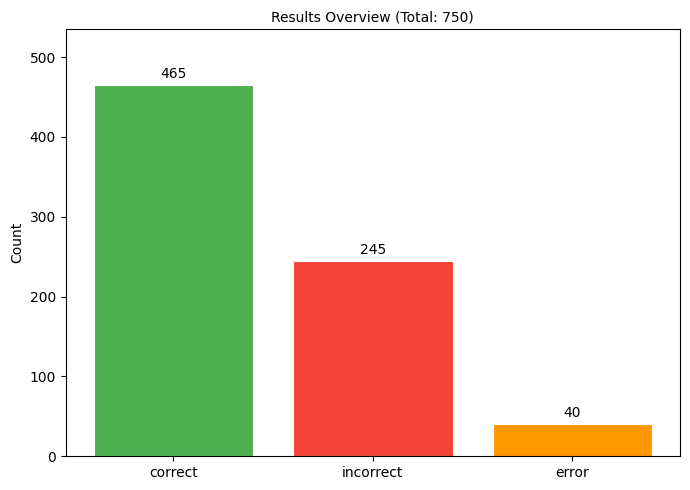

In [12]:
import matplotlib.pyplot as plt

categories = ['correct', 'incorrect', 'error']
values = [count_all[k] for k in categories]
colors = ['#4CAF50', '#F44336', '#FF9800']

fig, ax = plt.subplots(figsize=(7, 5))
ax.set_title('Results Overview (Total: 750)', fontsize=10)

bars = ax.bar(categories, values, color=colors, edgecolor='white', linewidth=0.8)
ax.set_ylabel('Count')
ax.set_ylim(0, max(values) * 1.15)
for bar, val in zip(bars, values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 5,
            str(val), ha='center', va='bottom')

plt.tight_layout()
plt.savefig('results_plot.png', dpi=150, bbox_inches='tight')
plt.show()

In [116]:
import sys
import os
from src.database_utils.execution import execute_sql, compare_sqls, _compare_sqls_outcomes

def compare_gold_predicted(db_path: str, predicted_sql: str, gold_sql: str):

    predicted_result = execute_sql(db_path, predicted_sql, fetch="all")
    gold_result = execute_sql(db_path, gold_sql, fetch="all")

    def get_columns(db_path: str, sql: str):
        with sqlite3.connect(db_path) as conn:
            cursor = conn.cursor()
            cursor.execute(sql)
            columns = [description[0] for description in cursor.description]
        return columns

    def print_result(label, sql, result):
        print(f"{label}")
        print(f"{bold('SQL')}: {sql.strip()}")
        print(f"\nTotal rows returned: {len(result)}")
        columns = get_columns(db_path, predicted_sql)
        if len(result) == 0:
            print("  (no rows returned)")
        else:
            for i, row in enumerate(result):
                if not isinstance(row, (tuple, list)):
                    row = (row,)
                print(f"  Row {i+1}:")
                for j, value in enumerate(row):
                    print(f"    {columns[j]}: {value}")
            print("_"*100 + "\n")

    print_result(f"{BLUE}{bold('PREDICTED SQL:')}{RESET}", predicted_sql, predicted_result)
    print_result(f"{GREEN}{bold('GOLD SQL:')}{RESET}", gold_sql, gold_result)

    print(f"{RED}{bold('COMPARISON:')}{RESET}")
    print(f"  Same number of rows : {len(predicted_result) == len(gold_result)}")
    print(f"  Exact match         : {predicted_result == gold_result}")
    print(f"  Set match (no order): {set(predicted_result) == set(gold_result)}")

    if predicted_result != gold_result:
        set_pred = set(predicted_result)
        set_gold = set(gold_result)
        only_in_pred = set_pred - set_gold
        only_in_gold = set_gold - set_pred
        if only_in_pred:
            print(f"\n  Rows only in PREDICTED:")
            for row in only_in_pred:
                print(f"    {row}")
        if only_in_gold:
            print(f"\n  Rows only in GOLD (missing from PREDICTED):")
            for row in only_in_gold:
                print(f"    {row}")
    else:
        print("\n  Results are identical.")

In [117]:
idx = 2

sqlite_path = pred_1[str(idx)].split("\t----- bird -----\t")[1]
db_path = f"./data/dev/dev_databases/{sqlite_path}/{sqlite_path}.sqlite"
predicted_sql = pred_1[str(idx)].split("\t----- bird -----\t")[0]
gold_sql = dev[idx]['SQL']

compare_gold_predicted(db_path, predicted_sql, gold_sql)

PREDICTED SQL:
SQL: SELECT T1.Zip FROM schools AS T1 INNER JOIN frpm AS T2 ON T1.CDSCode = T2.CDSCode WHERE T2.`Charter School (Y/N)` = 1 AND T2.`District Name` = 'Fresno County Office of Education'

Total rows returned: 5
  Row 1:
    Zip: 93726-5309
  Row 2:
    Zip: 93628-9602
  Row 3:
    Zip: 93706-2611
  Row 4:
    Zip: 93726-5208
  Row 5:
    Zip: 93706-2819
____________________________________________________________________________________________________

GOLD SQL:
SQL: SELECT T2.Zip FROM frpm AS T1 INNER JOIN schools AS T2 ON T1.CDSCode = T2.CDSCode WHERE T1.`District Name` = 'Fresno County Office of Education' AND T1.`Charter School (Y/N)` = 1

Total rows returned: 5
  Row 1:
    Zip: 93726-5309
  Row 2:
    Zip: 93628-9602
  Row 3:
    Zip: 93706-2611
  Row 4:
    Zip: 93726-5208
  Row 5:
    Zip: 93706-2819
____________________________________________________________________________________________________

COMPARISON:
  Same number of rows : True
  Exact match         : 